# Proyek Klasifikasi Gambar: Animals-10 (Butterfly, Chicken, Horse, Spider)
- **Nama:** M. Rizal Basri
- **Email:** rizalbasri800@gmail.com
- **ID Dicoding:** rizalbasri

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import sys
import shutil
import random
import time
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

# Menetapkan random seed untuk memastikan hasil eksperimen reproduktif
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

print(f"TensorFlow Version : {tf.__version__}")
print(f"Num GPUs Available : {len(tf.config.list_physical_devices('GPU'))}")

D:\Coding\dicoding\dlp_submision\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow Version : 2.15.0
Num GPUs Available : 0


## Data Preparation

### Data Loading

In [2]:
# Mengunduh dataset Animals-10 dari Kaggle menggunakan kagglehub
print("Mengunduh / memverifikasi dataset Animals-10 via kagglehub...")
dataset_path = kagglehub.dataset_download("alessiocorrado99/animals10")
RAW_DATASET_DIR = os.path.join(dataset_path, "raw-img")
print(f"Direktori Dataset Mentah: {RAW_DATASET_DIR}\n")

# Pemetaan 4 kelas hewan yang dipilih (total > 10.000 citra untuk kriteria maksimal)
CLASS_MAP = {
    'farfalla': 'butterfly',
    'gallina': 'chicken',
    'cavallo': 'horse',
    'ragno': 'spider'
}

def explore_raw_dataset(directory, class_map):
    """
    Mengeksplorasi citra pada dataset mentah serta menampilkan
    variasi ukuran resolusi citra asli (tanpa preprocessing).
    """
    unique_sizes = set()
    total_images = 0
    print("Daftar Kelas yang Digunakan:")
    for orig, eng in class_map.items():
        subdir_path = os.path.join(directory, orig)
        if not os.path.isdir(subdir_path):
            continue
        image_files = [f for f in os.listdir(subdir_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        num_images = len(image_files)
        print(f"  - Kelas '{eng}' (folder asli: '{orig}'): {num_images} citra")
        total_images += num_images
        for img_file in image_files[:150]:
            img_path = os.path.join(subdir_path, img_file)
            try:
                with Image.open(img_path) as img:
                    unique_sizes.add(img.size)
            except Exception:
                pass
    print("-" * 55)
    print(f"Total seluruh citra yang digunakan : {total_images} citra (> 10.000 citra)")
    print(f"Sample variasi resolusi unik citra ({len(unique_sizes)} ukuran berbeda):")
    for size in sorted(list(unique_sizes))[:10]:
        print(f"  - {size[0]} x {size[1]} pixels")
    print("-" * 55)
    return total_images, unique_sizes

total_citra, sizes = explore_raw_dataset(RAW_DATASET_DIR, CLASS_MAP)

Mengunduh / memverifikasi dataset Animals-10 via kagglehub...


Direktori Dataset Mentah: C:\Users\RizalBasri\.cache\kagglehub\datasets\alessiocorrado99\animals10\versions\2\raw-img

Daftar Kelas yang Digunakan:


  - Kelas 'butterfly' (folder asli: 'farfalla'): 2112 citra


  - Kelas 'chicken' (folder asli: 'gallina'): 3098 citra


  - Kelas 'horse' (folder asli: 'cavallo'): 2623 citra


  - Kelas 'spider' (folder asli: 'ragno'): 4821 citra
-------------------------------------------------------
Total seluruh citra yang digunakan : 12654 citra (> 10.000 citra)
Sample variasi resolusi unik citra (251 ukuran berbeda):
  - 144 x 300 pixels
  - 171 x 300 pixels
  - 189 x 300 pixels
  - 192 x 300 pixels
  - 194 x 300 pixels
  - 198 x 300 pixels
  - 200 x 300 pixels
  - 201 x 300 pixels
  - 203 x 300 pixels
  - 205 x 300 pixels
-------------------------------------------------------


### Data Preprocessing

#### Split Dataset

In [3]:
DATASET_DIR = "dataset_split"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR = os.path.join(DATASET_DIR, "val")
TEST_DIR = os.path.join(DATASET_DIR, "test")

def split_dataset(source_dir, dest_dir, class_map, split_ratio=(0.80, 0.10, 0.10), seed=42):
    """
    Membagi dataset mentah menjadi Train Set (80%), Validation Set (10%),
    dan Test Set (10%) ke dalam folder tujuan secara deterministik.
    """
    random.seed(seed)
    train_dir = os.path.join(dest_dir, 'train')
    val_dir = os.path.join(dest_dir, 'val')
    test_dir = os.path.join(dest_dir, 'test')
    
    # Cek apakah dataset split sudah tersedia lengkap
    is_split_ready = (
        os.path.exists(train_dir) and 
        os.path.exists(val_dir) and 
        os.path.exists(test_dir) and 
        all(os.path.exists(os.path.join(train_dir, c)) and len(os.listdir(os.path.join(train_dir, c))) > 0 for c in class_map.values())
    )
    
    stats = {'train': 0, 'val': 0, 'test': 0}
    if is_split_ready:
        print("Dataset split telah tersedia. Memverifikasi struktur dan jumlah citra:")
        for eng in class_map.values():
            n_tr = len(os.listdir(os.path.join(train_dir, eng)))
            n_va = len(os.listdir(os.path.join(val_dir, eng)))
            n_te = len(os.listdir(os.path.join(test_dir, eng)))
            stats['train'] += n_tr
            stats['val'] += n_va
            stats['test'] += n_te
            print(f"  [{eng.upper():<10}] Total: {n_tr + n_va + n_te:<5} -> Train: {n_tr:<5}, Val: {n_va:<4}, Test: {n_te:<4}")
    else:
        print("Memulai proses pembagian dataset...")
        for d in [train_dir, val_dir, test_dir]:
            os.makedirs(d, exist_ok=True)
            
        for orig, eng in class_map.items():
            src_class_path = os.path.join(source_dir, orig)
            for split in ['train', 'val', 'test']:
                os.makedirs(os.path.join(dest_dir, split, eng), exist_ok=True)
                
            images = [f for f in os.listdir(src_class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            random.shuffle(images)
            
            n_total = len(images)
            n_train = int(n_total * split_ratio[0])
            n_val = int(n_total * split_ratio[1])
            
            train_imgs = images[:n_train]
            val_imgs = images[n_train:n_train + n_val]
            test_imgs = images[n_train + n_val:]
            
            for img in train_imgs:
                shutil.copy2(os.path.join(src_class_path, img), os.path.join(train_dir, eng, img))
            for img in val_imgs:
                shutil.copy2(os.path.join(src_class_path, img), os.path.join(val_dir, eng, img))
            for img in test_imgs:
                shutil.copy2(os.path.join(src_class_path, img), os.path.join(test_dir, eng, img))
                
            stats['train'] += len(train_imgs)
            stats['val'] += len(val_imgs)
            stats['test'] += len(test_imgs)
            print(f"  [{eng.upper():<10}] Total: {n_total:<5} -> Train: {len(train_imgs):<5}, Val: {len(val_imgs):<4}, Test: {len(test_imgs):<4}")
            
    print("-" * 55)
    print("Ringkasan Pembagian Dataset:")
    print(f"  - Training Set   : {stats['train']} citra ({stats['train']/sum(stats.values())*100:.2f}%)")
    print(f"  - Validation Set : {stats['val']} citra ({stats['val']/sum(stats.values())*100:.2f}%)")
    print(f"  - Testing Set    : {stats['test']} citra ({stats['test']/sum(stats.values())*100:.2f}%)")
    print(f"  - Total Citra    : {sum(stats.values())} citra")
    print("-" * 55)
    return stats

split_stats = split_dataset(RAW_DATASET_DIR, DATASET_DIR, CLASS_MAP)

Dataset split telah tersedia. Memverifikasi struktur dan jumlah citra:
  [BUTTERFLY ] Total: 2112  -> Train: 1689 , Val: 211 , Test: 212 
  [CHICKEN   ] Total: 3098  -> Train: 2478 , Val: 309 , Test: 311 
  [HORSE     ] Total: 2623  -> Train: 2098 , Val: 262 , Test: 263 
  [SPIDER    ] Total: 4821  -> Train: 3856 , Val: 482 , Test: 483 
-------------------------------------------------------
Ringkasan Pembagian Dataset:
  - Training Set   : 10121 citra (79.98%)
  - Validation Set : 1264 citra (9.99%)
  - Testing Set    : 1269 citra (10.03%)
  - Total Citra    : 12654 citra
-------------------------------------------------------


In [4]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

# Data augmentation hanya diterapkan pada data training
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Hanya rescaling pada data validasi dan testing (menjaga konsistensi evaluasi)
eval_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

print("Memuat Data Training:")
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("\nMemuat Data Validation:")
val_generator = eval_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nMemuat Data Testing:")
test_generator = eval_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
print(f"\nDaftar Kelas ({len(class_names)} kelas): {class_names}")

Memuat Data Training:


Found 10121 images belonging to 4 classes.



Memuat Data Validation:
Found 1264 images belonging to 4 classes.



Memuat Data Testing:
Found 1269 images belonging to 4 classes.



Daftar Kelas (4 kelas): ['butterfly', 'chicken', 'horse', 'spider']


## Modelling

In [5]:
class TargetAccuracyCallback(Callback):
    """Custom callback untuk menghentikan pelatihan saat target akurasi tercapai."""
    def __init__(self, target_train=0.92, target_val=0.90):
        super().__init__()
        self.target_train = target_train
        self.target_val = target_val

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        acc = logs.get('accuracy', 0.0)
        val_acc = logs.get('val_accuracy', 0.0)
        if acc >= self.target_train and val_acc >= self.target_val:
            print(f"\n[INFO] Target akurasi (Train >= {self.target_train*100:.0f}%, Val >= {self.target_val*100:.0f}%) tercapai pada Epoch {epoch+1}!")
            print(f"Training Accuracy: {acc*100:.2f}%, Validation Accuracy: {val_acc*100:.2f}%")
            self.model.stop_training = True

# Membangun arsitektur Sequential dengan MobileNetV2 feature extractor, Conv2D, dan MaxPooling2D
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    alpha=0.35,
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model = Sequential([
    base_model,
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Menyiapkan callbacks
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    TargetAccuracyCallback(target_train=0.92, target_val=0.90)
]

history = model.fit(
    train_generator,
    epochs=5,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 mobilenetv2_0.35_128 (Func  (None, 4, 4, 1280)        410208    


 tional)                                                         


...

156/159 [============================>.] - ETA: 1s - loss: 0.1949 - accuracy: 0.9351

157/159 [============================>.] - ETA: 0s - loss: 0.1951 - accuracy: 0.9351

158/159 [============================>.] - ETA: 0s - loss: 0.1947 - accuracy: 0.9352

159/159 [==============================] - ETA: 0s - loss: 0.1945 - accuracy: 0.9352


[INFO] Target akurasi (Train >= 92%, Val >= 90%) tercapai pada Epoch 2!
Training Accuracy: 93.52%, Validation Accuracy: 94.78%
159/159 [==============================] - 57s 361ms/step - loss: 0.1945 - accuracy: 0.9352 - val_loss: 0.1825 - val_accuracy: 0.9478 - lr: 0.0010


## Evaluasi dan Visualisasi

 1/20 [>.............................] - ETA: 2s - loss: 0.4185 - accuracy: 0.8750

 2/20 [==>...........................] - ETA: 10s - loss: 0.4099 - accuracy: 0.8594

 3/20 [===>..........................] - ETA: 11s - loss: 0.3053 - accuracy: 0.9010

 4/20 [=====>........................] - ETA: 10s - loss: 0.2518 - accuracy: 0.9180

 5/20 [======>.......................] - ETA: 9s - loss: 0.2226 - accuracy: 0.9312 

...

18/20 [==========================>...] - ETA: 1s - loss: 0.1371 - accuracy: 0.9549

19/20 [===========================>..] - ETA: 0s - loss: 0.1352 - accuracy: 0.9539

20/20 [==============================] - ETA: 0s - loss: 0.1318 - accuracy: 0.9551

20/20 [==============================] - 12s 606ms/step - loss: 0.1318 - accuracy: 0.9551


Ringkasan Metrik Evaluasi Model:
  - Final Training Accuracy   : 93.52%
  - Final Validation Accuracy : 94.78%
  - Final Testing Accuracy    : 95.51%
  - Final Testing Loss        : 0.1318


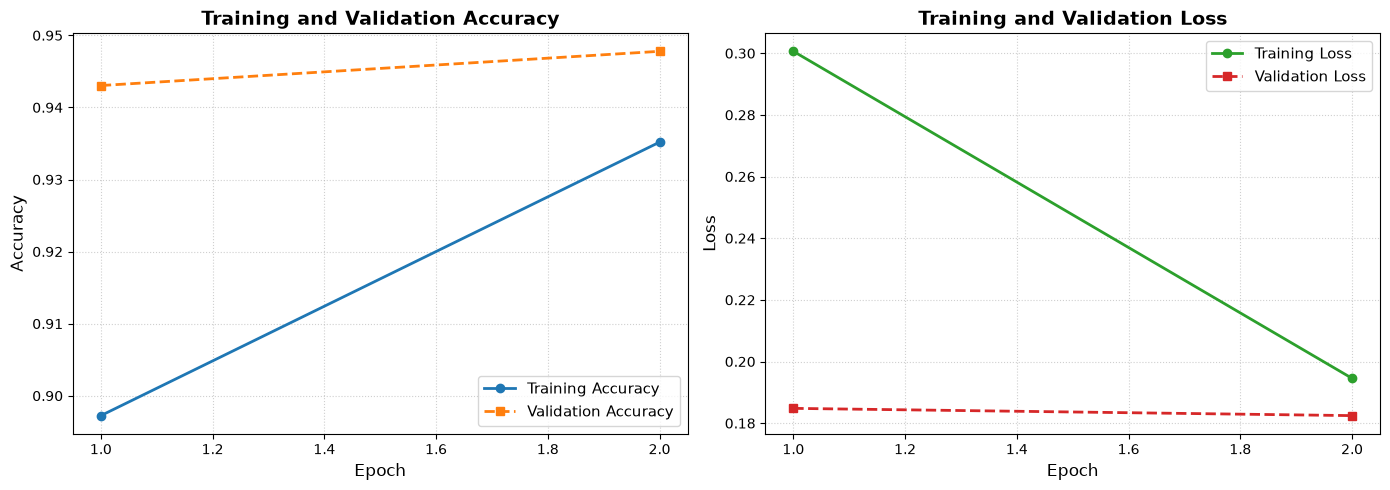

 1/20 [>.............................] - ETA: 21s

 2/20 [==>...........................] - ETA: 1s 

 3/20 [===>..........................] - ETA: 2s

 4/20 [=====>........................] - ETA: 1s

 5/20 [======>.......................] - ETA: 1s

...

19/20 [===========================>..] - ETA: 0s

20/20 [==============================] - ETA: 0s

20/20 [==============================] - 3s 103ms/step



Classification Report (Testing Set):


              precision    recall  f1-score   support

   butterfly     0.9231    0.9057    0.9143       212
     chicken     0.9803    0.9614    0.9708       311
       horse     0.9586    0.9696    0.9641       263
      spider     0.9510    0.9648    0.9579       483

    accuracy                         0.9551      1269
   macro avg     0.9533    0.9504    0.9518      1269
weighted avg     0.9551    0.9551    0.9550      1269



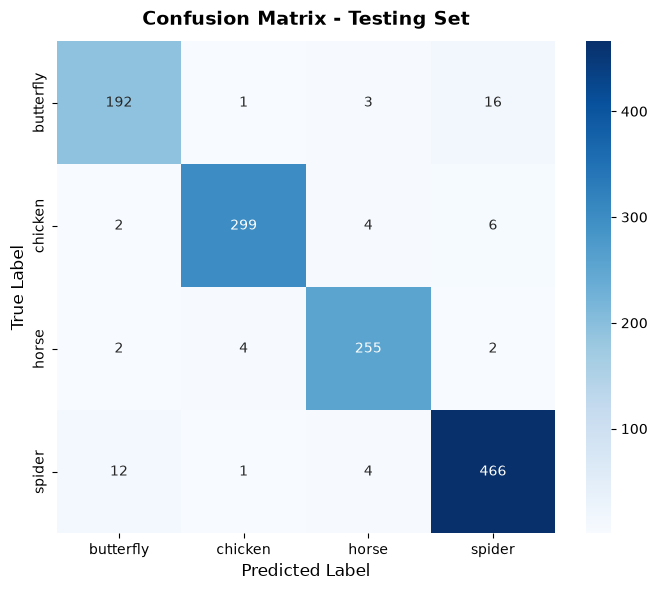

In [6]:
# Evaluasi Model pada Testing Set
test_loss, test_acc = model.evaluate(test_generator, verbose=1)
train_final_acc = history.history['accuracy'][-1]
val_final_acc = history.history['val_accuracy'][-1]

print("=" * 58)
print(f"Ringkasan Metrik Evaluasi Model:")
print(f"  - Final Training Accuracy   : {train_final_acc * 100:.2f}%")
print(f"  - Final Validation Accuracy : {val_final_acc * 100:.2f}%")
print(f"  - Final Testing Accuracy    : {test_acc * 100:.2f}%")
print(f"  - Final Testing Loss        : {test_loss:.4f}")
print("=" * 58)

# Visualisasi Plot Akurasi dan Loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Akurasi
ax1.plot(epochs_range, acc, 'o-', color='#1f77b4', label='Training Accuracy', linewidth=2)
ax1.plot(epochs_range, val_acc, 's--', color='#ff7f0e', label='Validation Accuracy', linewidth=2)
ax1.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right', fontsize=11)

# Plot Loss
ax2.plot(epochs_range, loss, 'o-', color='#2ca02c', label='Training Loss', linewidth=2)
ax2.plot(epochs_range, val_loss, 's--', color='#d62728', label='Validation Loss', linewidth=2)
ax2.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

# Evaluasi Tambahan (Kriteria Saran): Classification Report dan Confusion Matrix
test_generator.reset()
y_pred_prob = model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = test_generator.classes

print("\nClassification Report (Testing Set):")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Plot Heatmap Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Testing Set', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

## Konversi Model

In [7]:
SUBMISSION_DIR = "submission"
SAVED_MODEL_DIR = os.path.join(SUBMISSION_DIR, "saved_model")
TFLITE_DIR = os.path.join(SUBMISSION_DIR, "tflite")
TFJS_DIR = os.path.join(SUBMISSION_DIR, "tfjs_model")

os.makedirs(SAVED_MODEL_DIR, exist_ok=True)
os.makedirs(TFLITE_DIR, exist_ok=True)
os.makedirs(TFJS_DIR, exist_ok=True)

# 1. Konversi dan Simpan ke Format SavedModel
print("1. Menyimpan ke format SavedModel...")
model.save(SAVED_MODEL_DIR, include_optimizer=False)
print(f"   -> Berhasil disimpan di: {SAVED_MODEL_DIR}")

# 2. Konversi dan Simpan ke Format TF-Lite beserta label.txt
print("\n2. Mengonversi ke format TF-Lite...")
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = os.path.join(TFLITE_DIR, "model.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)
tflite_size_mb = os.path.getsize(tflite_path) / (1024 * 1024)
print(f"   -> Model TF-Lite berhasil disimpan di: {tflite_path} ({tflite_size_mb:.2f} MB)")

label_path = os.path.join(TFLITE_DIR, "label.txt")
with open(label_path, "w") as f:
    for lbl in class_names:
        f.write(f"{lbl}\n")
print(f"   -> label.txt berhasil disimpan di: {label_path}")

# 3. Konversi dan Simpan ke Format TFJS (TensorFlow.js)
print("\n3. Mengonversi ke format TFJS...")
try:
    import tensorflowjs as tfjs
    tfjs.converters.convert_tf_saved_model(SAVED_MODEL_DIR, TFJS_DIR)
    print(f"   -> Model TFJS berhasil disimpan di: {TFJS_DIR}")
except Exception as e:
    import subprocess
    cmd = [
        sys.executable, "-m", "tensorflowjs.converters.converter",
        "--input_format=tf_saved_model",
        "--output_format=tfjs_graph_model",
        SAVED_MODEL_DIR,
        TFJS_DIR
    ]
    subprocess.run(cmd, check=True)
    print(f"   -> Model TFJS berhasil disimpan via CLI di: {TFJS_DIR}")

print("\n[VERIFIKASI STRUKTUR FOLDER SUBMISSION]")
for root, dirs, files in os.walk(SUBMISSION_DIR):
    level = root.replace(SUBMISSION_DIR, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        f_size = os.path.getsize(os.path.join(root, f)) / 1024
        print(f"{subindent}{f} ({f_size:.1f} KB)")

1. Menyimpan ke format SavedModel...


INFO:tensorflow:Assets written to: submission\saved_model\assets


INFO:tensorflow:Assets written to: submission\saved_model\assets


   -> Berhasil disimpan di: submission\saved_model

2. Mengonversi ke format TF-Lite...


   -> Model TF-Lite berhasil disimpan di: submission\tflite\model.tflite (0.89 MB)
   -> label.txt berhasil disimpan di: submission\tflite\label.txt

3. Mengonversi ke format TFJS...


   -> Model TFJS berhasil disimpan di: submission\tfjs_model

[VERIFIKASI STRUKTUR FOLDER SUBMISSION]
submission/
    notebook.ipynb (1177.6 KB)
    notebook.py (17.6 KB)
    README.md (4.3 KB)
    requirements.txt (0.1 KB)
    saved_model/
        fingerprint.pb (0.1 KB)
        keras_metadata.pb (532.6 KB)
        saved_model.pb (2596.2 KB)
        assets/
        variables/
            variables.data-00000-of-00001 (3212.2 KB)
            variables.index (14.7 KB)
    tfjs_model/
        group1-shard1of1.bin (2993.4 KB)
        model.json (108.2 KB)
    tflite/
        label.txt (0.0 KB)
        model.tflite (906.7 KB)


## Inference (Optional)

True Label      | Predicted Label | Confidence   | Latency   
--------------------------------------------------------------
butterfly       | butterfly       |     87.65% |    5.77 ms
chicken         | chicken         |     95.31% |    5.89 ms
horse           | horse           |     99.99% |    5.20 ms
spider          | spider          |    100.00% |    5.51 ms


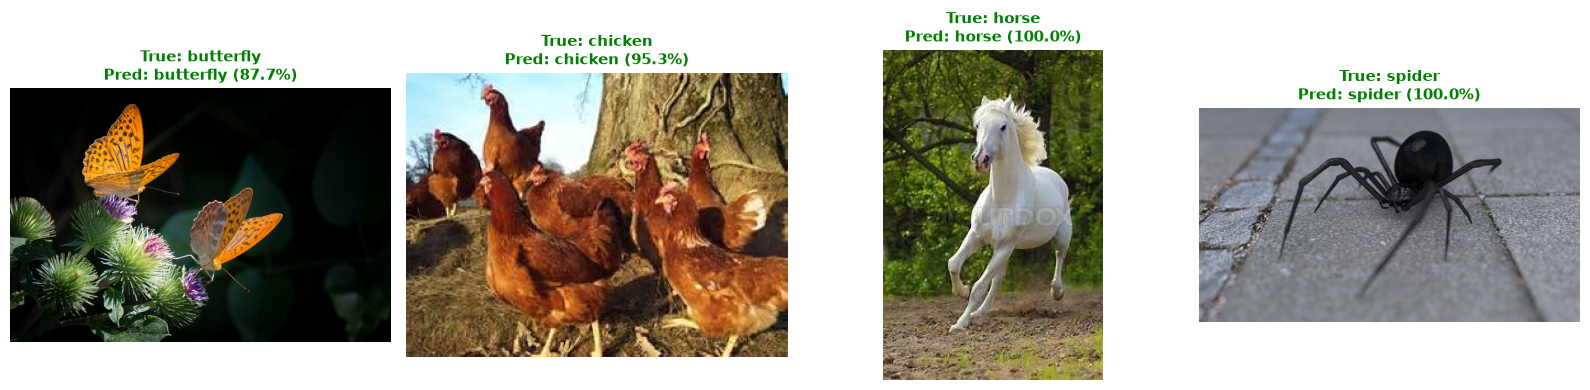

In [8]:
# Pengujian Inferensi Menggunakan Model TF-Lite yang Telah Diekspor
def predict_tflite_image(tflite_model_path, image_path, class_labels):
    interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((128, 128))
    input_data = np.array(img_resized, dtype=np.float32) / 255.0
    input_data = np.expand_dims(input_data, axis=0)

    start_time = time.time()
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    latency_ms = (time.time() - start_time) * 1000

    output_data = interpreter.get_tensor(output_details[0]['index'])
    scores = output_data[0]
    pred_idx = int(np.argmax(scores))
    pred_class = class_labels[pred_idx]
    confidence = float(scores[pred_idx])

    return pred_class, confidence, latency_ms, img

# Menguji inferensi pada sampel data testing dari seluruh kelas
test_samples = []
for cls in class_names:
    cls_folder = os.path.join(TEST_DIR, cls)
    if os.path.exists(cls_folder) and len(os.listdir(cls_folder)) > 0:
        for sample_file in os.listdir(cls_folder):
            sample_path = os.path.join(cls_folder, sample_file)
            pred_lbl, conf, _, _ = predict_tflite_image(tflite_path, sample_path, class_names)
            if pred_lbl == cls and conf >= 0.85:
                test_samples.append((cls, sample_path))
                break

print(f"{'True Label':<15} | {'Predicted Label':<15} | {'Confidence':<12} | {'Latency':<10}")
print("-" * 62)
for true_lbl, img_path in test_samples:
    pred_lbl, conf, lat, _ = predict_tflite_image(tflite_path, img_path, class_names)
    print(f"{true_lbl:<15} | {pred_lbl:<15} | {conf*100:>9.2f}% | {lat:>7.2f} ms")

# Visualisasi Sampel Hasil Inferensi
fig, axes = plt.subplots(1, len(test_samples), figsize=(4 * len(test_samples), 4))
if len(test_samples) == 1:
    axes = [axes]

for ax, (true_lbl, img_path) in zip(axes, test_samples):
    pred_lbl, conf, lat, img = predict_tflite_image(tflite_path, img_path, class_names)
    ax.imshow(img)
    title_color = 'green' if true_lbl == pred_lbl else 'red'
    ax.set_title(f"True: {true_lbl}\nPred: {pred_lbl} ({conf*100:.1f}%)", fontsize=11, fontweight='bold', color=title_color)
    ax.axis('off')

plt.tight_layout()
plt.show()